# Neural Networks for Digit Recognition
    Like we've discussed in the previous notebook neural networks are the state of the art when it comes to most complex problmes that machine learning algorithms fail to achieve the acme of performance

## Getting the data ready

In [1]:
from keras.datasets import mnist
from matplotlib import pyplot
(X_train, y_train), (X_test, y_test) = mnist.load_data()
from keras.utils import np_utils
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
pd.set_option('display.max_columns', 100) # Show all columns when looking at dataframe
import warnings
warnings.filterwarnings('ignore') # remove warnings from the notebook

Using TensorFlow backend.


In [2]:
# load data
(X_train, y_train), (X_test, y_test) = mnist.load_data()
# flatten 28*28 images to a 784 vector for each image
num_pixels = X_train.shape[1] * X_train.shape[2]
X_train = X_train.reshape(X_train.shape[0], num_pixels).astype( 'float32' )
X_test = X_test.reshape(X_test.shape[0], num_pixels).astype( 'float32' )
# normalize inputs from 0-255 to 0-1
X_train = X_train / 255
X_test = X_test / 255
# one hot encode outputs
y_train = np_utils.to_categorical(y_train)
y_test = np_utils.to_categorical(y_test)
num_classes = y_test.shape[1]

*Now its time!!! To introduce you to Neural Networks*

![Ta-Da](https://www.tibco.com/blog/wp-content/uploads/2015/11/tada.png)

# NEURAL NETWORKS

**NOTE: It is a digit recognition task. As such there are 10 digits (0 to 9) or 10 classes to predict. Results are reported using prediction error, which is nothing more than the inverted classification accuracy. Excellent results achieve a prediction error of less than 1%. State-of-the-art prediction error of approximately 0.2% can be achieved with large Convolutional Neural Networks.**

*Lets Kick off with a base line Multilayer Perceptron Model*

In [3]:
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Dropout

## Multilayer Perceptrons Model

Do we really need a complex model like a convolutional neural network to get the best results with MNIST? You can get good results using a very simple neural network model with a single hidden layer. In this section we will create a simple Multilayer Perceptron model that achieves an error rate of 1.48%.

In [4]:
# create model
model = Sequential()
model.add(Dense(num_pixels, input_dim= num_pixels, init= 'normal' , activation= 'relu' ))
model.add(Dense(num_classes, init= 'normal' , activation= 'softmax' ))
# Compile model
model.compile(loss= 'categorical_crossentropy' , optimizer= 'adam' , metrics=[ 'accuracy' ])

*Lets See the model Summary*

In [5]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_1 (Dense)              (None, 784)               615440    
_________________________________________________________________
dense_2 (Dense)              (None, 10)                7850      
Total params: 623,290
Trainable params: 623,290
Non-trainable params: 0
_________________________________________________________________


The model is a simple neural network with one hidden layer with the same number of neurons as there are inputs (784). A rectifier activation function is used for the neurons in the hidden layer. A softmax activation function is used on the output layer to turn the outputs into probability-like values and allow one class of the 10 to be selected as the model’s output19.3. Baseline Model with Multilayer Perceptrons 125 prediction. Logarithmic loss is used as the loss function (called categorical crossentropy in Keras) and the e!cient ADAM gradient descent algorithm is used to learn the weights.

![MultilayerPerceptron](https://i.ibb.co/8mFcvMB/mlp.png)

In [6]:
#fit the model
model_info= model.fit(X_train, y_train, validation_data=(X_test, y_test), nb_epoch=20, batch_size=200, verbose=2)
model_info;

Train on 60000 samples, validate on 10000 samples
Epoch 1/20
 - 15s - loss: 0.2818 - accuracy: 0.9196 - val_loss: 0.1403 - val_accuracy: 0.9595
Epoch 2/20
 - 15s - loss: 0.1118 - accuracy: 0.9678 - val_loss: 0.0939 - val_accuracy: 0.9716
Epoch 3/20
 - 15s - loss: 0.0713 - accuracy: 0.9792 - val_loss: 0.0774 - val_accuracy: 0.9750
Epoch 4/20
 - 14s - loss: 0.0511 - accuracy: 0.9848 - val_loss: 0.0704 - val_accuracy: 0.9775
Epoch 5/20
 - 14s - loss: 0.0364 - accuracy: 0.9898 - val_loss: 0.0662 - val_accuracy: 0.9793
Epoch 6/20
 - 14s - loss: 0.0264 - accuracy: 0.9929 - val_loss: 0.0604 - val_accuracy: 0.9805
Epoch 7/20
 - 14s - loss: 0.0205 - accuracy: 0.9948 - val_loss: 0.0588 - val_accuracy: 0.9802
Epoch 8/20
 - 14s - loss: 0.0145 - accuracy: 0.9968 - val_loss: 0.0586 - val_accuracy: 0.9811
Epoch 9/20
 - 14s - loss: 0.0103 - accuracy: 0.9979 - val_loss: 0.0624 - val_accuracy: 0.9808
Epoch 10/20
 - 14s - loss: 0.0102 - accuracy: 0.9978 - val_loss: 0.0604 - val_accuracy: 0.9814
Epoch 11/

In [7]:
# Final evaluation of the model
scores = model.evaluate(X_test, y_test, verbose=0)
print(f"Accuracy: {scores[1]*100:.2f} %")
print(f"Baseline Error: {(100-scores[1]*100):.2f} ")

Accuracy: 98.40 %
Baseline Error: 1.60 


*Lets plot model accuracy and loss on train and test*

In [15]:
def plot_model_history(model_history):
    fig, axs = plt.subplots(1,2,figsize=(15,5))
    # summarize history for accuracy
    axs[0].plot(range(1,len(model_history.history['accuracy'])+1),model_history.history['accuracy'])
    axs[0].plot(range(1,len(model_history.history['val_accuracy'])+1),model_history.history['val_accuracy'])
    axs[0].set_title('Model Accuracy')
    axs[0].set_ylabel('Accuracy')
    axs[0].set_xlabel('Epoch')
    axs[0].set_xticks(np.arange(1,len(model_history.history['accuracy'])+1),len(model_history.history['accuracy'])/10)
    axs[0].legend(['train', 'val'], loc='best')
    # summarize history for loss
    axs[1].plot(range(1,len(model_history.history['loss'])+1),model_history.history['loss'])
    axs[1].plot(range(1,len(model_history.history['val_loss'])+1),model_history.history['val_loss'])
    axs[1].set_title('Model Loss')
    axs[1].set_ylabel('Loss')
    axs[1].set_xlabel('Epoch')
    axs[1].set_xticks(np.arange(1,len(model_history.history['loss'])+1),len(model_history.history['loss'])/10)
    axs[1].legend(['train', 'val'], loc='best')
    plt.show()


def accuracy(test_x, test_y, model):
    result = model.predict(test_x)
    predicted_class = np.argmax(result, axis=1)
    true_class = np.argmax(test_y, axis=1)
    num_correct = np.sum(predicted_class == true_class) 
    accuracy = float(num_correct)/result.shape[0]
    return (accuracy * 100)

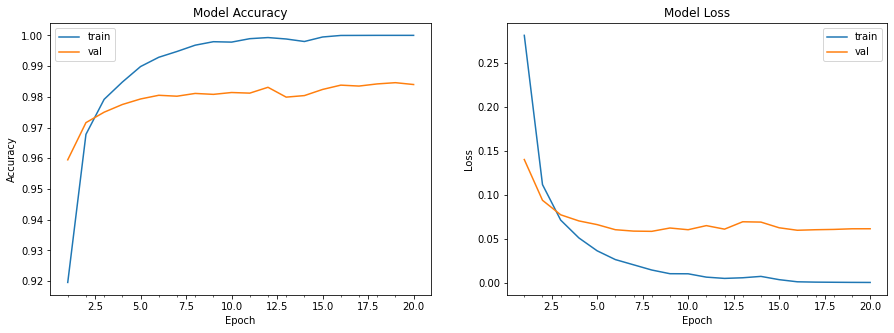

In [16]:
plot_model_history(model_info)

*On the Model accuracy plot on the left you can see that there is a bit high value at Number of Epochs  arounf 7 and 8,  So Somewhere around number of epochs 7, you will get the high accuracy .*

*From this it is clear that Even after using a simple Multi-layer Perceptraon model, we are getting a accuracy of around 98.5%, Which is great.!!!*

In [17]:
results = pd.DataFrame([['Multi-Layer Perceptron Model', f" {scores[1]*100:.2f} %"]], columns = ['Model', 'Accuracy'])
results 

,Model,Accuracy
0,Multi-Layer Perceptron Model,98.40 %


**Wait is over!! TIme has arrived to introduce you to What we called State-of-the-art and the model you have been wailting even before the beginning of the Data Tale**

## Convolutional Neural Network

*Convolutional Neural Networks are a powerful artificial neural network technique. These networks preserve the spatial structure of the problem and were developed for object recognition tasks such as handwritten digit recognition. They are popular because people are achieving state-of-the-art results on di!cult computer vision and natural language processing tasks.*

Now that we have seen how to train a simple Multilayer Perceptron model , it is time to develop a more sophisticated convolutional neural network or CNN model. Keras does provide a lot of capability for creating convolutional neural networks. In this section we will create a simple CNN for MNIST that demonstrates how to use all of the aspects of a modern CNN implementation, including Convolutional layers, Pooling layers and Dropout layers. 

In [18]:
from keras.layers import Flatten
from keras.layers.convolutional import Conv2D
from keras.layers.convolutional import MaxPooling2D

##Simple Convolutional Neural Network

Convolutional neural networks are more complex than standard Multilayer Perceptrons, so we will start by using a simple model to begin with that uses all of the elements for state-of-the-art results. 



*In Keras, the layers used for two-dimensional convolutions expect pixel values with the dimensions [pixels][width][height].*

*n the case of RGB, the first dimension pixels would be 3 for the red, green and blue components and it would be like having 3 image inputs for every color image. In the case of MNIST where the pixel values are gray scale, the pixel dimension is set to 1.*

In [19]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train = X_train.reshape(X_train.shape[0], 1, 28, 28).astype('float32')
X_test = X_test.reshape(X_test.shape[0], 1, 28, 28).astype('float32')
# normalize inputs from 0-255 to 0-1
X_train = X_train / 255
X_test = X_test / 255
# one hot encode outputs
y_train = np_utils.to_categorical(y_train)
y_test = np_utils.to_categorical(y_test)
num_classes = y_test.shape[1]

In [20]:
# create model
model = Sequential()
model.add(Conv2D(32, (5, 5), input_shape=(1, 28, 28), activation='relu',data_format='channels_first'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.2))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dense(num_classes, activation='softmax'))
# Compile model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

*Lets Check the Summary*

In [21]:
model.summary()

Model: "sequential_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_1 (Conv2D)            (None, 32, 24, 24)        832       
_________________________________________________________________
max_pooling2d_1 (MaxPooling2 (None, 16, 12, 24)        0         
_________________________________________________________________
dropout_1 (Dropout)          (None, 16, 12, 24)        0         
_________________________________________________________________
flatten_1 (Flatten)          (None, 4608)              0         
_________________________________________________________________
dense_3 (Dense)              (None, 128)               589952    
_________________________________________________________________
dense_4 (Dense)              (None, 10)                1290      
Total params: 592,074
Trainable params: 592,074
Non-trainable params: 0
________________________________________________

**A Brief Summary: **

- The first hidden layer is a convolutional layer called a Convolution2D. The layer has 32 feature maps, which with the size of 5 ⇥ 5 and a rectifier activation function. This is the input layer, expecting images with the structure outline above.
- Next we define a pooling layer that takes the maximum value called MaxPooling2D. It is configured with a pool size of 2 ⇥ 2.
- The next layer is a regularization layer using dropout called Dropout. It is configured to randomly exclude 20% of neurons in the layer in order to reduce overfitting.
-  Next is a layer that converts the 2D matrix data to a vector called Flatten. It allows the output to be processed by standard fully connected layers.
- Next a fully connected layer with 128 neurons and rectifier activation function is used.
- Finally, the output layer has 10 neurons for the 10 classes and a softmax activation function to output probability-like predictions for each class.

*As before, the model is trained using logarithmic loss and the ADAM gradient descent algorithm.*

![Simple_CNN](https://i.ibb.co/GHRGFQR/simpCNN.png)


In [22]:
# Fit the model
model_info= model.fit(X_train, y_train, validation_data=(X_test, y_test), nb_epoch=10, batch_size=200, verbose=2)
model_info;

Train on 60000 samples, validate on 10000 samples
Epoch 1/10
 - 64s - loss: 0.2401 - accuracy: 0.9286 - val_loss: 0.0777 - val_accuracy: 0.9767
Epoch 2/10
 - 67s - loss: 0.0776 - accuracy: 0.9768 - val_loss: 0.0611 - val_accuracy: 0.9803
Epoch 3/10
 - 63s - loss: 0.0552 - accuracy: 0.9830 - val_loss: 0.0508 - val_accuracy: 0.9825
Epoch 4/10
 - 94s - loss: 0.0422 - accuracy: 0.9866 - val_loss: 0.0442 - val_accuracy: 0.9853
Epoch 5/10
 - 43s - loss: 0.0351 - accuracy: 0.9889 - val_loss: 0.0384 - val_accuracy: 0.9873
Epoch 6/10
 - 35s - loss: 0.0284 - accuracy: 0.9911 - val_loss: 0.0358 - val_accuracy: 0.9873
Epoch 7/10
 - 36s - loss: 0.0243 - accuracy: 0.9921 - val_loss: 0.0328 - val_accuracy: 0.9890
Epoch 8/10
 - 36s - loss: 0.0202 - accuracy: 0.9937 - val_loss: 0.0361 - val_accuracy: 0.9886
Epoch 9/10
 - 36s - loss: 0.0176 - accuracy: 0.9942 - val_loss: 0.0387 - val_accuracy: 0.9878
Epoch 10/10
 - 36s - loss: 0.0136 - accuracy: 0.9957 - val_loss: 0.0351 - val_accuracy: 0.9887


In [23]:
# Final evaluation of the model
scores = model.evaluate(X_test, y_test, verbose=0)
print(f"Accuracy: {scores[1]*100:.2f} %")
print(f"Simple CNN Error: {(100-scores[1]*100):.2f} ")

Accuracy: 98.87 %
Simple CNN Error: 1.13 


In [26]:
def plot_model_history(model_history):
    fig, axs = plt.subplots(1,2,figsize=(15,5))
    # summarize history for accuracy
    axs[0].plot(range(1,len(model_history.history['accuracy'])+1),model_history.history['accuracy'])
    axs[0].plot(range(1,len(model_history.history['val_accuracy'])+1),model_history.history['val_accuracy'])
    axs[0].set_title('Model Accuracy')
    axs[0].set_ylabel('Accuracy')
    axs[0].set_xlabel('Epoch')
    axs[0].set_xticks(np.arange(1,len(model_history.history['accuracy'])+1),len(model_history.history['accuracy'])/10)
    axs[0].legend(['train', 'val'], loc='best')
    # summarize history for loss
    axs[1].plot(range(1,len(model_history.history['loss'])+1),model_history.history['loss'])
    axs[1].plot(range(1,len(model_history.history['val_loss'])+1),model_history.history['val_loss'])
    axs[1].set_title('Model Loss')
    axs[1].set_ylabel('Loss')
    axs[1].set_xlabel('Epoch')
    axs[1].set_xticks(np.arange(1,len(model_history.history['loss'])+1),len(model_history.history['loss'])/10)
    axs[1].legend(['train', 'val'], loc='best')
    plt.show()


def accuracy(test_x, test_y, model):
    result = model.predict(test_x)
    predicted_class = np.argmax(result, axis=1)
    true_class = np.argmax(test_y, axis=1)
    num_correct = np.sum(predicted_class == true_class) 
    accuracy = float(num_correct)/result.shape[0]
    return (accuracy * 100)

*Lets Plot Model Accuracy and loss*

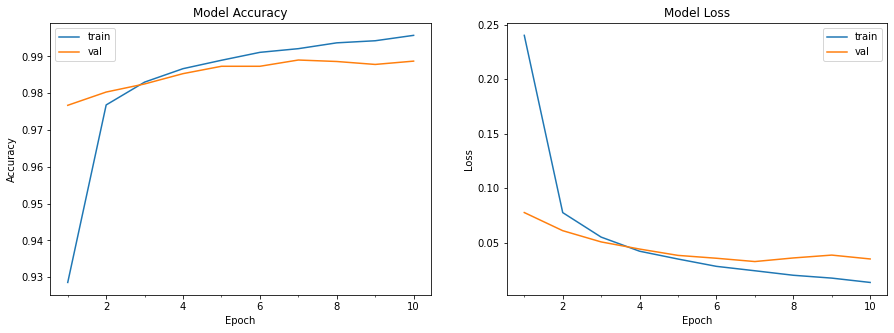

In [27]:
plot_model_history(model_info)

*You can clearly see the at Number of epochs 5 we got a high accuracy of 99%. If you try to stop at Number of Epochs 5, You will get a error rate 1.0  and this shows that this performs better then Multilayer Perceptron Model, Which was very obvious*

In [28]:
model_results = pd.DataFrame([['Simple Convolutional Neural Network', f" {scores[1]*100:.2f} %"]], columns = ['Model', 'Accuracy'])
results = results.append(model_results, ignore_index = True)
results 

,Model,Accuracy
0,Multi-Layer Perceptron Model,98.40 %
1,Simple Convolutional Neural Network,98.87 %


## Larger Convolutional Neural Network

*Now that we have seen how to create a simple CNN, let’s take a look at a model capable of close to state-of-the-art results. We import the classes and functions then load and prepare the data the same as in the previous CNN example. This time we define a larger CNN architecture with additional convolutional, max pooling layers and fully connected layers.*

In [29]:
# create model
model = Sequential()
model.add(Conv2D(30, (5, 5), input_shape=(1, 28, 28), activation='relu', data_format='channels_first'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Conv2D(15, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.2))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dense(50, activation='relu'))
model.add(Dense(num_classes, activation='softmax'))
# Compile model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

*Lets Get the Model Summary*

In [30]:
model.summary()

Model: "sequential_3"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_2 (Conv2D)            (None, 30, 24, 24)        780       
_________________________________________________________________
max_pooling2d_2 (MaxPooling2 (None, 15, 12, 24)        0         
_________________________________________________________________
conv2d_3 (Conv2D)            (None, 13, 10, 15)        3255      
_________________________________________________________________
max_pooling2d_3 (MaxPooling2 (None, 6, 5, 15)          0         
_________________________________________________________________
dropout_2 (Dropout)          (None, 6, 5, 15)          0         
_________________________________________________________________
flatten_2 (Flatten)          (None, 450)               0         
_________________________________________________________________
dense_5 (Dense)              (None, 128)              

**A brief Summary**

- Convolutional layer with 30 feature maps of size 5 x 5.
-  Pooling layer taking the max over 2 x 2 patches.
-  Convolutional layer with 15 feature maps of size 3 x 3.
-  Pooling layer taking the max over 2 x 2 patches.
-  Dropout layer with a probability of 20%.
-  Flatten layer.
-  Fully connected layer with 128 neurons and rectifier activation.19.5. Larger Convolutional Neural Network for MNIST 132
-  Fully connected layer with 50 neurons and rectifier activation.
-  Output layer


![LargerCNN](https://i.ibb.co/YDLc8RP/largecnn.png)

In [31]:
# Fit the model
model_info= model.fit(X_train, y_train, validation_data=(X_test, y_test), nb_epoch=20, batch_size=200, verbose=2)
model_info;

Train on 60000 samples, validate on 10000 samples
Epoch 1/20
 - 22s - loss: 0.4595 - accuracy: 0.8594 - val_loss: 0.1319 - val_accuracy: 0.9606
Epoch 2/20
 - 22s - loss: 0.1370 - accuracy: 0.9591 - val_loss: 0.0810 - val_accuracy: 0.9763
Epoch 3/20
 - 21s - loss: 0.0958 - accuracy: 0.9706 - val_loss: 0.0579 - val_accuracy: 0.9820
Epoch 4/20
 - 22s - loss: 0.0781 - accuracy: 0.9758 - val_loss: 0.0480 - val_accuracy: 0.9845
Epoch 5/20
 - 23s - loss: 0.0642 - accuracy: 0.9791 - val_loss: 0.0439 - val_accuracy: 0.9861
Epoch 6/20
 - 27s - loss: 0.0579 - accuracy: 0.9811 - val_loss: 0.0411 - val_accuracy: 0.9858
Epoch 7/20
 - 27s - loss: 0.0489 - accuracy: 0.9843 - val_loss: 0.0400 - val_accuracy: 0.9855
Epoch 8/20
 - 25s - loss: 0.0434 - accuracy: 0.9862 - val_loss: 0.0333 - val_accuracy: 0.9886
Epoch 9/20
 - 24s - loss: 0.0387 - accuracy: 0.9871 - val_loss: 0.0327 - val_accuracy: 0.9894
Epoch 10/20
 - 24s - loss: 0.0376 - accuracy: 0.9877 - val_loss: 0.0331 - val_accuracy: 0.9880
Epoch 11/

In [32]:
# Final evaluation of the model
scores = model.evaluate(X_test, y_test, verbose=0)
print(f"Accuracy: {scores[1]*100:.2f} %")
print(f"Baseline Error: {(100-scores[1]*100):.2f} ")

Accuracy: 98.96 %
Baseline Error: 1.04 


*Great We achieve a Accuracy of 99.16, Now Lets plot the  accuracy and loss*

In [33]:
def plot_model_history(model_history):
    fig, axs = plt.subplots(1,2,figsize=(15,5))
    # summarize history for accuracy
    axs[0].plot(range(1,len(model_history.history['accuracy'])+1),model_history.history['accuracy'])
    axs[0].plot(range(1,len(model_history.history['val_accuracy'])+1),model_history.history['val_accuracy'])
    axs[0].set_title('Model Accuracy')
    axs[0].set_ylabel('Accuracy')
    axs[0].set_xlabel('Epoch')
    axs[0].set_xticks(np.arange(1,len(model_history.history['accuracy'])+1),len(model_history.history['accuracy'])/10)
    axs[0].legend(['train', 'val'], loc='best')
    # summarize history for loss
    axs[1].plot(range(1,len(model_history.history['loss'])+1),model_history.history['loss'])
    axs[1].plot(range(1,len(model_history.history['val_loss'])+1),model_history.history['val_loss'])
    axs[1].set_title('Model Loss')
    axs[1].set_ylabel('Loss')
    axs[1].set_xlabel('Epoch')
    axs[1].set_xticks(np.arange(1,len(model_history.history['loss'])+1),len(model_history.history['loss'])/10)
    axs[1].legend(['train', 'val'], loc='best')
    plt.show()


def accuracy(test_x, test_y, model):
    result = model.predict(test_x)
    predicted_class = np.argmax(result, axis=1)
    true_class = np.argmax(test_y, axis=1)
    num_correct = np.sum(predicted_class == true_class) 
    accuracy = float(num_correct)/result.shape[0]
    return (accuracy * 100)

*Lets Plot Model Accuracy and loss*

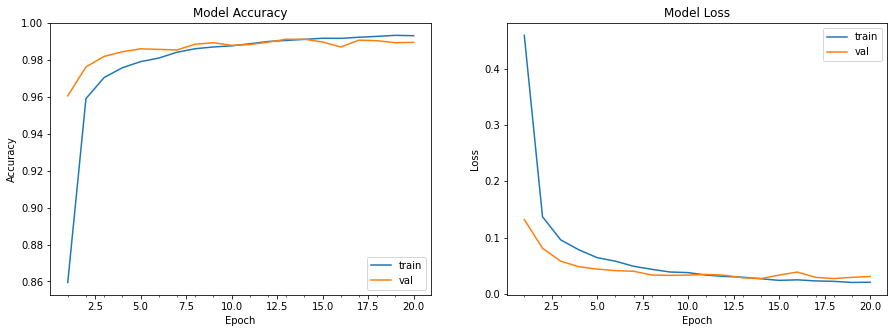

In [34]:
plot_model_history(model_info)

*From the above we can see how the model converges from a value of 0.86 to 0.99 for accuracy, No Doubt this is the best model we have got till now.*

In [35]:
model_results = pd.DataFrame([['Larger Convolutional Neural Network', f" {scores[1]*100:.2f} %"]], columns = ['Model', 'Accuracy'])
results = results.append(model_results, ignore_index = True)
results 

,Model,Accuracy
0,Multi-Layer Perceptron Model,98.40 %
1,Simple Convolutional Neural Network,98.87 %
2,Larger Convolutional Neural Network,98.96 %


*From the above results No doubt Larger Convolutional Neural Network is the best performing model.*

*Now lets see how to save a pretrained model of Keras*

In [36]:
# save model and architecture to single file
model.save("model.h5")
print("Saved model to disk")

Saved model to disk


*And to load a model use the following code*

In [37]:
from keras.models import load_model
# load model
model = load_model('model.h5')
# summarize model.
model.summary()

Model: "sequential_3"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_2 (Conv2D)            (None, 30, 24, 24)        780       
_________________________________________________________________
max_pooling2d_2 (MaxPooling2 (None, 15, 12, 24)        0         
_________________________________________________________________
conv2d_3 (Conv2D)            (None, 13, 10, 15)        3255      
_________________________________________________________________
max_pooling2d_3 (MaxPooling2 (None, 6, 5, 15)          0         
_________________________________________________________________
dropout_2 (Dropout)          (None, 6, 5, 15)          0         
_________________________________________________________________
flatten_2 (Flatten)          (None, 450)               0         
_________________________________________________________________
dense_5 (Dense)              (None, 128)              

*After trying out different machine learning models Lets see What perfromance we have got!!*

In [38]:
results

,Model,Accuracy
0,Multi-Layer Perceptron Model,98.40 %
1,Simple Convolutional Neural Network,98.87 %
2,Larger Convolutional Neural Network,98.96 %
